# 03.2 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/02-knn-by-hand/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


## Exercise 1

- to C012: $\sqrt{(12-14)^2 + (10-12)^2} = \sqrt{4 + 4} = 2.83$
- to C014: $\sqrt{(12-11)^2 + (10-8)^2} = \sqrt{1 + 4} = 2.24$ ← nearest
- to C006: $\sqrt{(12-13)^2 + (10-20)^2} = \sqrt{1 + 100} = 10.05$

All three stayed, so k = 3 predicts **stay**. (The true 3 nearest among all 20 may differ; the code checks.)

In [2]:
from sklearn.neighbors import KNeighborsClassifier
q = pd.DataFrame([[12, 10]], columns=X20.columns)
knn3 = KNeighborsClassifier(n_neighbors=3).fit(X20, y20)
d, idx = knn3.kneighbors(q)
print("nearest:", list(cust20.loc[idx[0], "customer_id"]), d.round(2), "→", knn3.predict(q))

nearest: ['C014', 'C012', 'C006'] [[ 2.24  2.83 10.05]] → [0]


## Exercise 2

k= 1: 75%
k= 3: 60%
k= 5: 65%
k= 7: 70%
k= 9: 50%
k=11: 60%
k=13: 40%
k=15: 55%
k=17: 55%
k=19: 55%


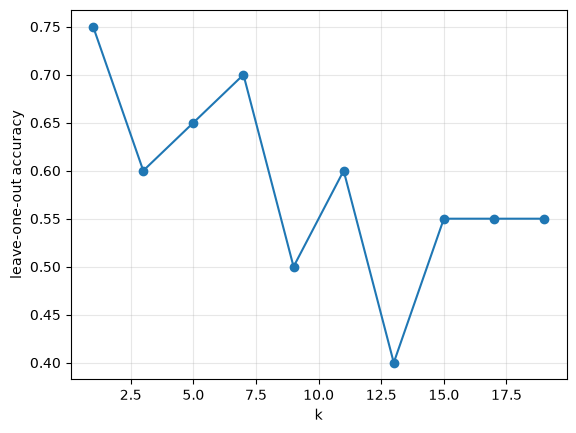

In [3]:
from sklearn.model_selection import cross_val_score, LeaveOneOut
ks = list(range(1, 20, 2))
accs = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X20, y20, cv=LeaveOneOut()).mean() for k in ks]
for k, a in zip(ks, accs):
    print(f"k={k:>2}: {a:.0%}")
plt.plot(ks, accs, marker="o"); plt.xlabel("k"); plt.ylabel("leave-one-out accuracy"); plt.grid(alpha=.3); plt.show()

With only 20 rows the curve is bumpy and several k tie. That is normal: tiny datasets cannot distinguish between nearby hyperparameter values. The point of the exercise is the *method*, which you will use on real data in Module 04.

## Exercise 3

In [4]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def compare(cols):
    raw = KNeighborsClassifier(15).fit(X_train[cols], y_train).score(X_test[cols], y_test)
    sc = make_pipeline(StandardScaler(), KNeighborsClassifier(15)).fit(X_train[cols], y_train).score(X_test[cols], y_test)
    print(f"{str(cols):<70} unscaled {raw:.1%}  scaled {sc:.1%}")

compare(features)
compare([f for f in features if f != "spend"])
print()
print(X_train.std().round(0))

['orders', 'spend', 'products', 'tenure_days', 'days_since_last']      unscaled 66.0%  scaled 64.5%
['orders', 'products', 'tenure_days', 'days_since_last']               unscaled 65.3%  scaled 64.8%

orders                5.0
spend              5348.0
products             62.0
tenure_days          78.0
days_since_last      77.0
dtype: float64


`spend` has a standard deviation in the thousands; `orders` in single digits. Unscaled, the distance is almost entirely about spend, and spend happens to be a decent churn predictor on its own, so unscaled KNN does fine *by accident*. Remove `spend` and the unscaled distance is now mostly `tenure_days` and `days_since_last` (std ≈ 77 each), which are also decent predictors, so the accident continues. The accuracies barely move either way; the lesson is that **you cannot tell which features an unscaled KNN is actually using** without looking at the standard deviations. Scale, so that the answer is "all of them, equally".

## Exercise 4

In [6]:
from sklearn.neighbors import KNeighborsRegressor
new = np.array([6, 30])
dist = np.sqrt(((X20.values - new) ** 2).sum(axis=1))
idx5 = np.argsort(dist)[:5]
print("neighbours:", list(cust20.loc[idx5, "customer_id"]))
print("mean spend of neighbours:", cust20.loc[idx5, "spend_next_month"].mean().round(2))

reg = KNeighborsRegressor(n_neighbors=5).fit(X20, cust20["spend_next_month"])
print("KNeighborsRegressor:", reg.predict(pd.DataFrame([new], columns=X20.columns)).round(2))

neighbours: ['C010', 'C005', 'C013', 'C016', 'C019']
mean spend of neighbours: 171.15
KNeighborsRegressor: [171.15]
